<a href="https://colab.research.google.com/github/Siyagour26/Datheon-Machine-Learning---Data-Science-Internship/blob/internship-task-3/Task_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install xgboost imbalanced-learn

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

from imblearn.over_sampling import SMOTE

In [4]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


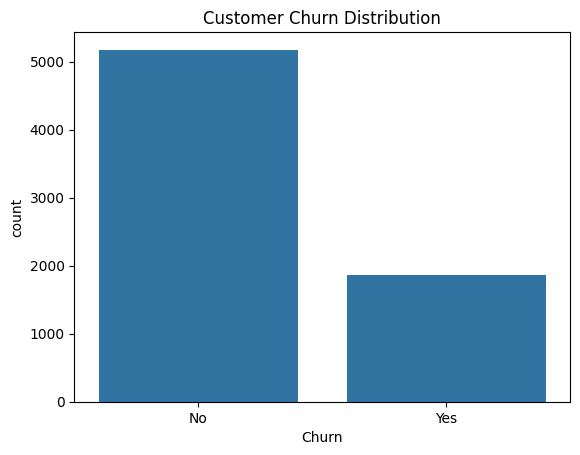

In [6]:
df['Churn'].value_counts()
sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.show()

In [7]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [8]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
df.drop('customerID', axis=1, inplace=True)

In [10]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", df[col].unique())

gender : ['Female' 'Male']
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn : ['No' 'Yes']


In [12]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


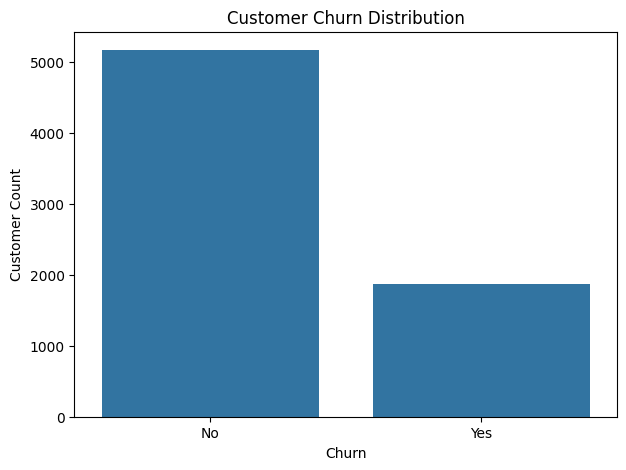

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Customer Count')

plt.show()

In [14]:
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

In [15]:
X = df.drop('Churn', axis=1)

y = df['Churn']

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(include='object').columns

print("Numerical columns:", num_cols.tolist())
print("Categorical columns:", cat_cols.tolist())

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [18]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [19]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [20]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [21]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [22]:
print("Training shape:", X_train_processed.shape)

print("Testing shape:", X_test_processed.shape)

Training shape: (5634, 45)
Testing shape: (1409, 45)


In [23]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

In [24]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight=None
)

rf_model.fit(X_train_balanced, y_train_balanced)

RandomForestClassifier(random_state=42)

In [26]:
y_pred_rf = rf_model.predict(X_test_processed)

y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nROC-AUC Score:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.7693399574166075

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.85      0.84      1035
           1       0.57      0.55      0.56       374

    accuracy                           0.77      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409


Confusion Matrix:
[[877 158]
 [167 207]]

ROC-AUC Score: 0.8138546591232012


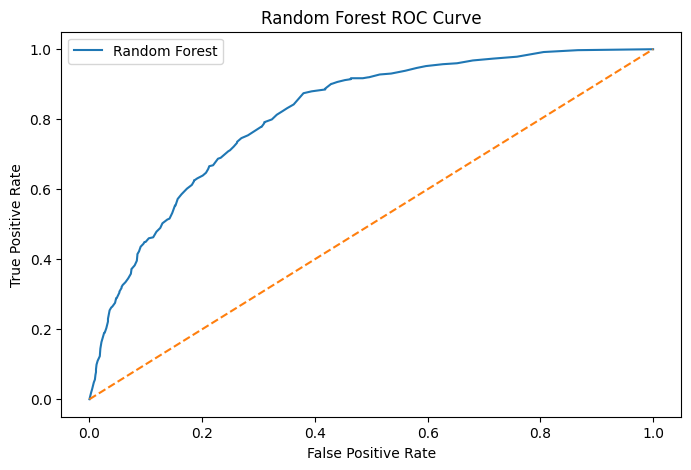

In [28]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")

plt.legend()
plt.show()

In [30]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
1,num__tenure,0.111089
3,num__TotalCharges,0.106577
2,num__MonthlyCharges,0.095543
36,cat__Contract_Month-to-month,0.074153
18,cat__OnlineSecurity_No,0.056843
43,cat__PaymentMethod_Electronic check,0.048450
38,cat__Contract_Two year,0.039025
27,cat__TechSupport_No,0.036141
16,cat__InternetService_Fiber optic,0.026155
40,cat__PaperlessBilling_Yes,0.024137


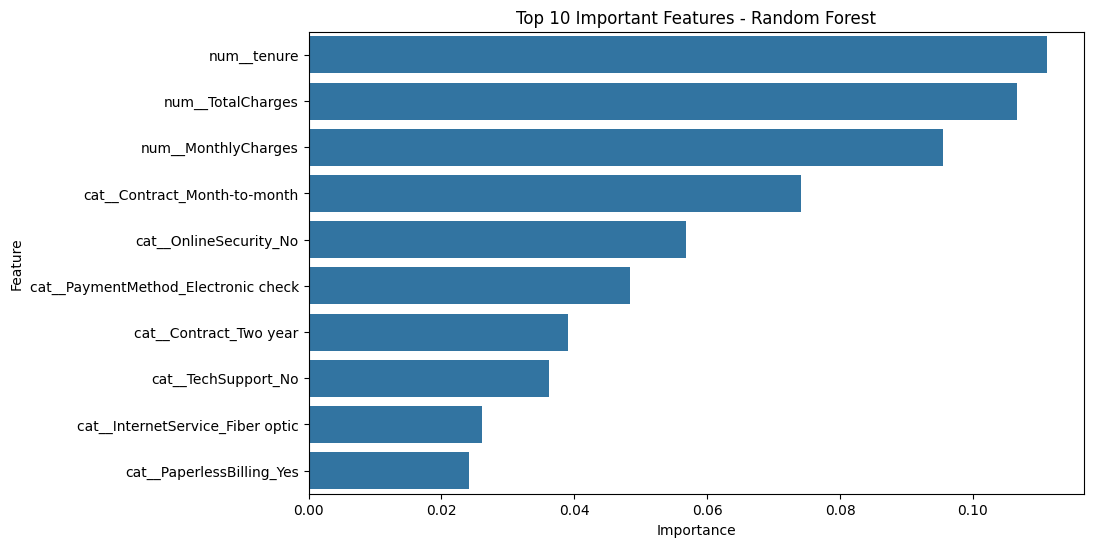

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.show()

In [32]:
scale_pos_weight = (
    y_train_balanced.value_counts()[0] /
    y_train_balanced.value_counts()[1]
)

print(scale_pos_weight)

1.0


In [33]:
scale_pos_weight = (
    y_train_balanced.value_counts()[0] /
    y_train_balanced.value_counts()[1]
)

print(scale_pos_weight)

1.0


In [34]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(
    X_train_balanced,
    y_train_balanced
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [35]:
y_pred_xgb = xgb_model.predict(X_test_processed)

y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nROC-AUC Score:", roc_auc_score(y_test, y_prob_xgb))

Accuracy: 0.7714691270404542

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.78      1409


Confusion Matrix:
[[854 181]
 [141 233]]

ROC-AUC Score: 0.8360936733059494


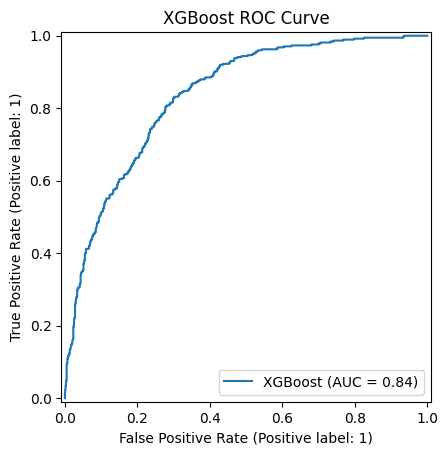

In [37]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb,
    name="XGBoost"
)

plt.title("XGBoost ROC Curve")
plt.show()

In [38]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    rf_model,
    X_train_balanced,
    y_train_balanced,
    cv=5,
    scoring='roc_auc'
)

xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train_balanced,
    y_train_balanced,
    cv=5,
    scoring='roc_auc'
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())

print("\nXGBoost CV Scores:", xgb_cv_scores)
print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

Random Forest CV Scores: [0.882145   0.88740767 0.96539155 0.96025665 0.96093864]
Random Forest Mean ROC-AUC: 0.9312279019632029

XGBoost CV Scores: [0.86351198 0.87729294 0.9794985  0.97899252 0.97814404]
XGBoost Mean ROC-AUC: 0.9354879953642218


In [39]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.769340,0.567123,0.553476,0.560217,0.813855
1,XGBoost,0.771469,0.562802,0.622995,0.591371,0.836094


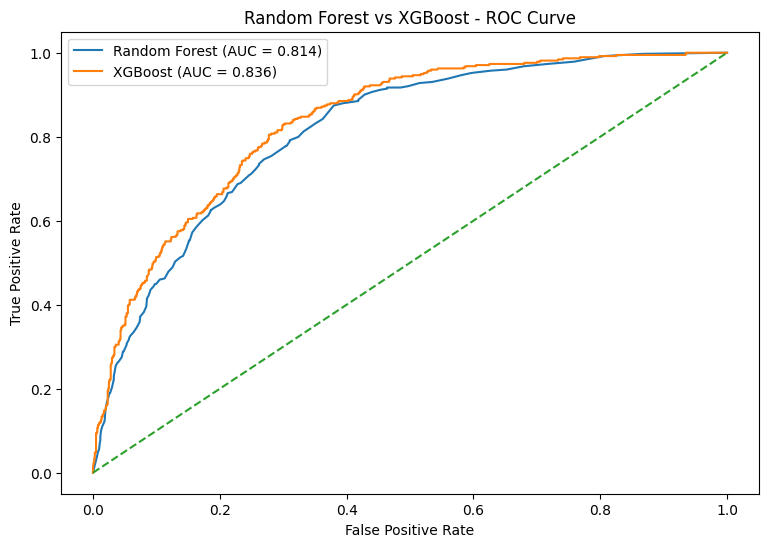

In [40]:
from sklearn.metrics import roc_curve

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})"
)

plt.plot(
    fpr_xgb, tpr_xgb,
    label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest vs XGBoost - ROC Curve")

plt.legend()
plt.show()

In [41]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Random Forest': rf_model.feature_importances_
})

xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'XGBoost': xgb_model.feature_importances_
})

importance_comparison = pd.merge(
    rf_importance,
    xgb_importance,
    on='Feature'
)

importance_comparison.head()

,Feature,Random Forest,XGBoost
0,num__SeniorCitizen,0.013716,0.003108
1,num__tenure,0.111089,0.016967
2,num__MonthlyCharges,0.095543,0.008444
3,num__TotalCharges,0.106577,0.006422
4,cat__gender_Female,0.015736,0.013495


In [42]:
rf_top10 = rf_importance.sort_values(
    by='Random Forest',
    ascending=False
).head(10)

xgb_top10 = xgb_importance.sort_values(
    by='XGBoost',
    ascending=False
).head(10)

print("Random Forest Top 10 Features:")
display(rf_top10)

print("\nXGBoost Top 10 Features:")
display(xgb_top10)

Random Forest Top 10 Features:


,Feature,Random Forest
1,num__tenure,0.111089
3,num__TotalCharges,0.106577
2,num__MonthlyCharges,0.095543
36,cat__Contract_Month-to-month,0.074153
18,cat__OnlineSecurity_No,0.056843
43,cat__PaymentMethod_Electronic check,0.048450
38,cat__Contract_Two year,0.039025
27,cat__TechSupport_No,0.036141
16,cat__InternetService_Fiber optic,0.026155
40,cat__PaperlessBilling_Yes,0.024137



XGBoost Top 10 Features:


,Feature,XGBoost
36,cat__Contract_Month-to-month,0.355100
16,cat__InternetService_Fiber optic,0.113182
18,cat__OnlineSecurity_No,0.075488
27,cat__TechSupport_No,0.037126
43,cat__PaymentMethod_Electronic check,0.033233
37,cat__Contract_One year,0.026002
35,cat__StreamingMovies_Yes,0.025668
8,cat__Dependents_No,0.023419
21,cat__OnlineBackup_No,0.023199
39,cat__PaperlessBilling_No,0.021383


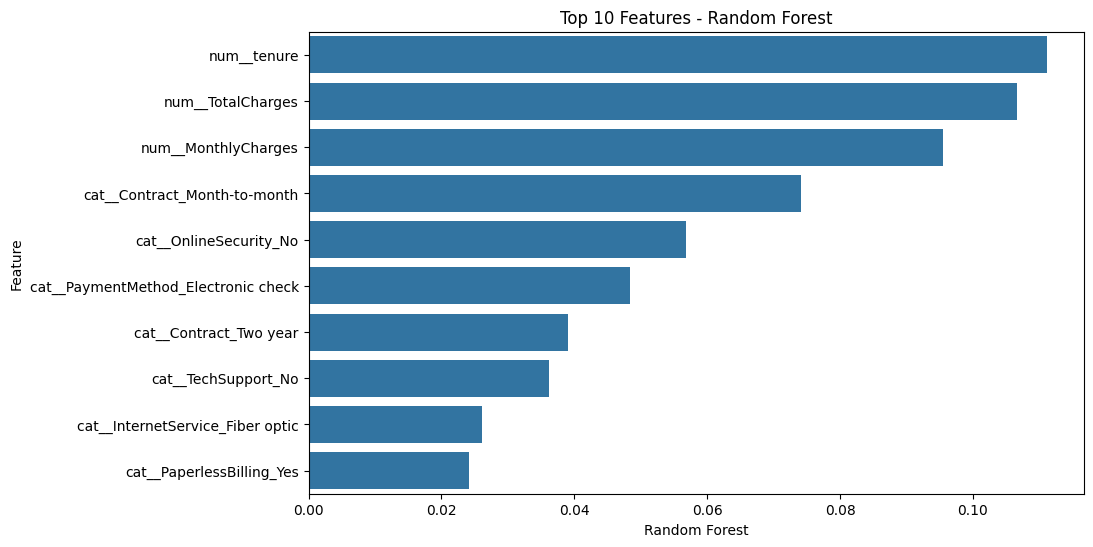

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_top10,
    x='Random Forest',
    y='Feature'
)

plt.title("Top 10 Features - Random Forest")
plt.show()

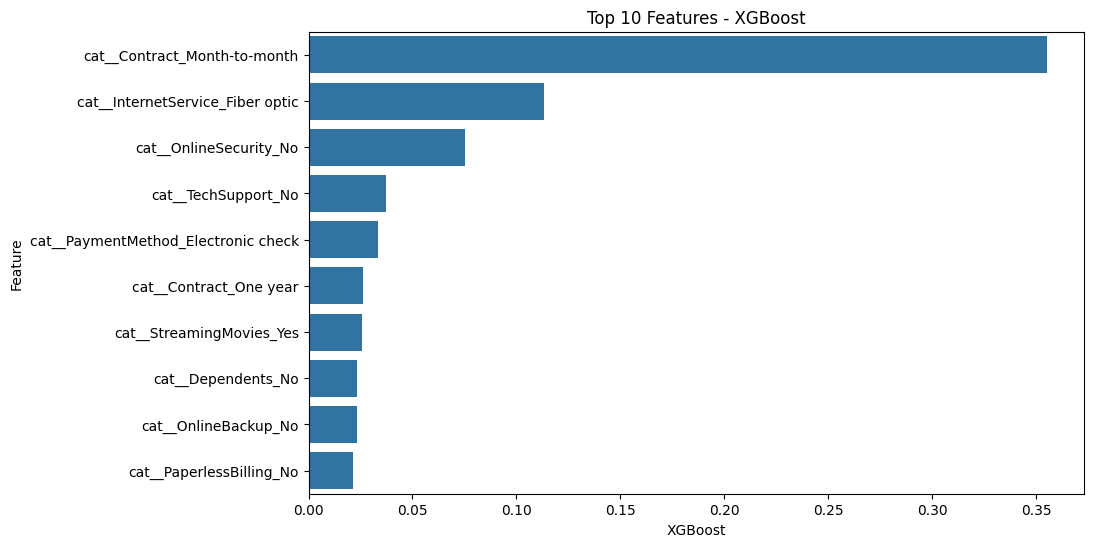

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_top10,
    x='XGBoost',
    y='Feature'
)

plt.title("Top 10 Features - XGBoost")
plt.show()

In [45]:
best_model = (
    rf_model
    if roc_auc_score(y_test, y_prob_rf) >
       roc_auc_score(y_test, y_prob_xgb)
    else xgb_model
)

print("Best Model:", type(best_model).__name__)

Best Model: XGBClassifier


In [47]:

from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

rf_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

xgb_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='logloss'
    ))
])

In [48]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

xgb_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("Random Forest CV Scores:", rf_scores)
print("Random Forest Mean:", rf_scores.mean())

print("\nXGBoost CV Scores:", xgb_scores)
print("XGBoost Mean:", xgb_scores.mean())

Random Forest CV Scores: [0.8079387  0.80036111 0.82014121 0.81007141 0.83322482]
Random Forest Mean: 0.8143474498085992

XGBoost CV Scores: [0.83299    0.82974852 0.84063424 0.85261257 0.85118472]
XGBoost Mean: 0.8414340104956655


In [49]:
rf_pipeline.fit(X_train, y_train)

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [50]:
y_prob_rf_final = rf_pipeline.predict_proba(X_test)[:, 1]

y_prob_xgb_final = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf_final))

print("XGBoost ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb_final))

Random Forest ROC-AUC: 0.8138546591232012
XGBoost ROC-AUC: 0.8360936733059494


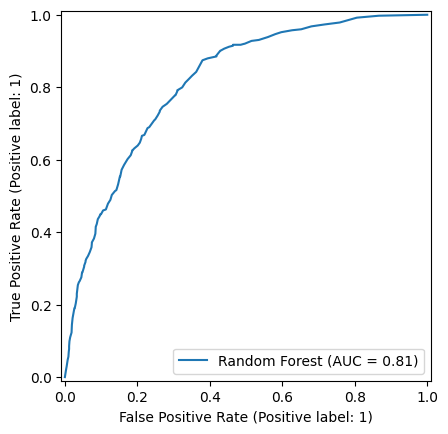

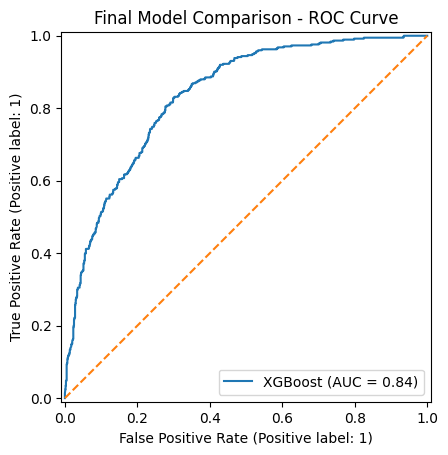

In [51]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf_final,
    name="Random Forest"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb_final,
    name="XGBoost"
)

plt.plot([0, 1], [0, 1], '--')

plt.title("Final Model Comparison - ROC Curve")
plt.show()

In [52]:
final_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'CV ROC-AUC': [rf_scores.mean(), xgb_scores.mean()],
    'Test ROC-AUC': [
        roc_auc_score(y_test, y_prob_rf_final),
        roc_auc_score(y_test, y_prob_xgb_final)
    ]
})

display(final_comparison)

,Model,CV ROC-AUC,Test ROC-AUC
0,Random Forest,0.814347,0.813855
1,XGBoost,0.841434,0.836094
